# O "pobre de direita": onde a base da sociedade vota na direita?

Dados públicos do TSE (votos por município, 2002–2026) e do IBGE (Censo 2022). Mesma base e mesma classificação de partidos dos notebooks anteriores (`src/partido_ideologia.py`).

**Leitura obrigatória antes dos números:**
- **Não existe "pobre" nos dados de votação.** O voto é secreto e o TSE não cruza voto com renda individual. Só observo **municípios**: renda média, religião, cor/raça, escolaridade. Dizer "municípios mais pobres votam X" **não** é dizer "pobres votam X" (falácia ecológica). Uma cidade rica tem pobres; uma cidade pobre tem remediados.
- Por isso este notebook responde a pergunta **"em que tipo de lugar o voto na direita é forte?"**, e não **"por que o pobre vota na direita?"**. A segunda precisa de pesquisa de opinião com renda individual (ESEB, Datafolha, Quaest, AtlasIntel); ver seção 8.
- "Direita" é classificação minha. Até 2014 o PSDB (centro) era o adversário do PT, então a "direita" quase não aparece em eleição presidencial antes de 2018. Para comparar o período todo, uso a **% de esquerda**.
- A premissa de que a direita "se preocupa pouco com os pobres" é um julgamento político. Os dados mostram **como as pessoas votam**, não **o que elas valorizam ao votar**. Só pesquisa individual ajuda a separar motivos.
- Só votos nominais, 1º turno, sem exterior. 2026 é o 1º turno de 4/10/2026.

## Resumo

A pergunta original ("por que a base vota em quem se preocupa pouco com ela?") **não pode ser respondida só com dados de votação**: não há renda individual. O que dá para responder é *em que tipo de lugar* o voto na direita é forte. Resultados (presidente, 1º turno; "pobre" = quintil de renda média do município):

**1. Nos lugares mais pobres do país, a direita é minoria.** No quintil mais pobre (23,5 milhões de eleitores, 2.136 municípios, quase todos no Nordeste e Norte) a esquerda tem 66% em 2026 e a direita 30%. A "direita entre os pobres" **não** é o padrão nos extremos de pobreza.

**2. A relação renda × voto não é constante.** Em 2002 os 20% mais pobres davam *menos* esquerda que os demais (54% contra 66–69%). Em 2006 isso inverte (72% contra 50–64%) e a diferença entre mais pobres e mais ricos chega a +41 p.p. em 2018, caindo para +27 em 2026. A esquerda perdeu mais nos quintis 2 a 5 do que no quintil 1.

**3. A faixa logo acima da mais pobre é onde a direita ganha.** Quintis 2 a 5 estão entre 50% e 59% de direita em 2026 (média ponderada). Fora do Nordeste, a maioria dos municípios do quintil 2 já dá mais direita que esquerda (53–57%), e até o quintil 1 fora do Nordeste dá 40–47%.

**4. Em números absolutos, a base de direita não é só rica.** Os quintis 1+2 dão 51% dos votos de esquerda e 33% dos de direita, mas somam **19,5 milhões de votos de direita** (11,4 milhões fora do Nordeste). Municípios de renda média-baixa são parte relevante da base da direita.

**5. Para o Legislativo, o gradiente de renda some.** Em 2022 o voto em partidos de direita para deputado federal foi de ~47% em *todos* os quintis, inclusive no mais pobre (onde Lula teve 73% de esquerda para presidente). Em 2026 o quintil mais pobre deu 41% para deputado federal e 39% para senador, contra 30% para presidente. O eleitor desses lugares escolhe presidente de forma bem diferente de como escolhe Congresso.

**6. O que separa os municípios dentro do mesmo estado:** cor/raça (+10 p.p. de esquerda por desvio-padrão de pretos e pardos, estável desde 2006) e, desde 2018, religião evangélica (−5,6 p.p.). A renda média, depois desses controles, acrescenta pouco (−2 p.p.). Entre os municípios abaixo da mediana de renda a renda volta a pesar: +1 DP de renda = +9,9 p.p. de direita.

**Cuidados:** tudo é nível de município (falácia ecológica); a classificação de partidos é minha; nada aqui testa *motivos* do voto. A seção 8 lista o que falta (survey individual, Bolsa Família, seção eleitoral × escolaridade).


## 1. Dados

Para cada município e eleição presidencial: % de voto em esquerda/centro/direita. Para "pobre" uso **quintis de renda média municipal ponderados por votos** (cada quintil tem ~20% dos eleitores), fixados em 2022 para todos os anos. Renda = rendimento nominal médio mensal das pessoas de 14+ (Censo 2022).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import statsmodels.formula.api as smf

pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:.1f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COR = {"esquerda": "#c0392b", "centro": "#95a5a6", "direita": "#1f4e9c"}
P = "../data/processed/"

ide = pd.read_csv(P + "partido_ideologia.csv")
mun = pd.read_parquet(P + "municipios_tse.parquet")
ib = pd.read_parquet(P + "ibge_perfil_extra.parquet")
v = pd.read_parquet(P + "votos_partido_municipio.parquet")
v = v[(v.NR_TURNO == 1) & v.CD_MUNICIPIO.isin(mun.CD_MUNICIPIO)].merge(ide, on="SG_PARTIDO", how="left")
assert v.ideologia.notna().all()

REG = {"Norte": "AC AM AP PA RO RR TO", "Nordeste": "AL BA CE MA PB PE PI RN SE", "Centro-Oeste": "DF GO MS MT",
       "Sudeste": "ES MG RJ SP", "Sul": "PR RS SC"}
UF2REG = {u: r for r, l in REG.items() for u in l.split()}

vot = v.pivot_table(index=["cargo", "ano", "CD_MUNICIPIO"], columns="ideologia", values="QT_VOTOS_NOMINAIS",
                    aggfunc="sum", fill_value=0)
vot["tot"] = vot.sum(axis=1)
for k in ("esquerda", "centro", "direita"):
    vot[k[:3]] = 100 * vot[k] / vot.tot
d = (vot.reset_index().merge(mun, on="CD_MUNICIPIO")
        .merge(ib[["CD_MUNICIPIO", "renda", "pop", "pct_urbano", "pct_evang", "pct_preta_parda", "pct_inst_baixa", "pct_superior"]],
               on="CD_MUNICIPIO"))
d["reg"] = d.SG_UF.map(UF2REG)
d = d.dropna(subset=["renda"])

# quintis de renda ponderados pelos votos presidenciais de 2022 (fixos)
b = d[(d.cargo == "presidente") & (d.ano == 2022)][["CD_MUNICIPIO", "renda", "tot"]].sort_values("renda")
b["q"] = np.ceil(b.tot.cumsum() / b.tot.sum() * 5).clip(1, 5).astype(int)
d = d.merge(b[["CD_MUNICIPIO", "q"]], on="CD_MUNICIPIO")
print("Faixas de renda média municipal (R$/mês) por quintil de eleitores:")
print(b.groupby("q").agg(municipios=("renda", "size"), renda_min=("renda", "min"), renda_max=("renda", "max"),
                         eleitores_mi=("tot", lambda s: s.sum() / 1e6)).round(1).to_string())
print()
print(d[(d.cargo == "presidente") & (d.ano == 2022)].groupby(["q", "reg"]).tot.sum().unstack("reg").div(1e6).round(1).to_string())
pres = d[d.cargo == "presidente"]
w = lambda g, c: np.average(g[c], weights=g.tot)

Faixas de renda média municipal (R$/mês) por quintil de eleitores:
   municipios  renda_min  renda_max  eleitores_mi
q                                                
1        2136      471.5     1173.1          23.5
2        1564     1173.2     1695.1          23.7
3        1082     1695.4     2077.0          23.6
4         647     2077.4     2771.2          23.5
5         138     2774.9     5178.2          23.7

reg  Centro-Oeste  Nordeste  Norte  Sudeste  Sul
q                                               
1             0.1      18.3    3.6      1.5  0.0
2             1.5       7.0    3.4     10.4  1.4
3             2.1       3.1    2.5     11.6  4.2
4             2.1       4.1    NaN     10.0  7.3
5             3.0       0.0    0.2     15.9  4.6


## 2. O gradiente renda × voto mudou de sinal duas vezes

% de esquerda no voto presidencial, por quintil de renda do município (Q1 = 20% mais pobres dos eleitores). Uso esquerda (e não direita) para ter série comparável desde 2002.

Se "o pobre vota na esquerda" fosse uma constante, as linhas ficariam sempre em ordem Q1 > Q2 > ... > Q5.

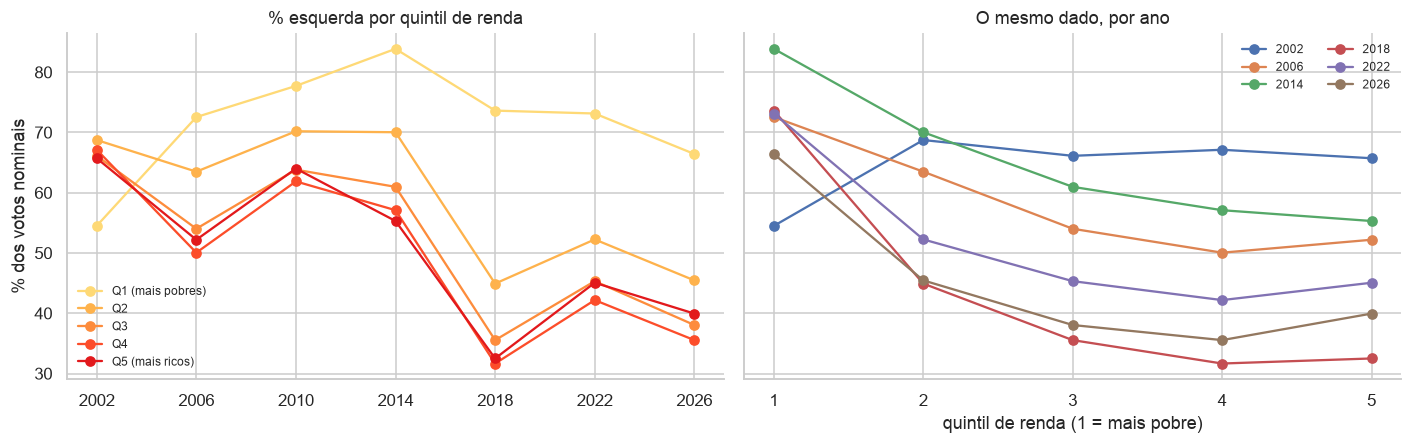

% esquerda
q       1    2    3    4    5
ano                          
2002 54.5 68.7 66.1 67.1 65.7
2006 72.5 63.5 54.0 50.0 52.2
2010 77.7 70.2 63.8 61.9 64.0
2014 83.9 70.0 61.0 57.1 55.3
2018 73.6 44.9 35.5 31.7 32.5
2022 73.1 52.2 45.3 42.2 45.1
2026 66.4 45.5 38.0 35.5 39.9

Diferença Q1 − Q5 (p.p. de esquerda):
ano
2002   -11.2
2006    20.4
2010    13.7
2014    28.6
2018    41.1
2022    28.1
2026    26.5


In [2]:
g = pres.groupby(["ano", "q"]).apply(lambda x: w(x, "esq")).unstack("q")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
pal = sns.color_palette("YlOrRd", 7)[1:6]
for q in range(1, 6):
    ax[0].plot(g.index, g[q], marker="o", color=pal[q - 1], label=f"Q{q}" + (" (mais pobres)" if q == 1 else " (mais ricos)" if q == 5 else ""))
ax[0].legend(frameon=False, fontsize=8); ax[0].set_title("% esquerda por quintil de renda"); ax[0].set_ylabel("% dos votos nominais")
ax[0].set_xticks(g.index)
for y in (2002, 2006, 2014, 2018, 2022, 2026):
    ax[1].plot(range(1, 6), g.loc[y], marker="o", label=y)
ax[1].set_xlabel("quintil de renda (1 = mais pobre)"); ax[1].set_title("O mesmo dado, por ano"); ax[1].legend(frameon=False, fontsize=8, ncol=2)
ax[1].set_xticks(range(1, 6))
plt.tight_layout(); plt.show()
print("% esquerda"); print(g.round(1).to_string())
print("\nDiferença Q1 − Q5 (p.p. de esquerda):"); print((g[1] - g[5]).round(1).to_string())

**Como ler:** em 2002 os 20% mais pobres davam *menos* esquerda que os demais (Lula perdia entre os mais pobres). A partir de 2006 (Bolsa Família, salário mínimo; o "lulismo" de André Singer) os mais pobres viram o grupo mais à esquerda. Depois de 2018 a esquerda cai nos quintis 2 a 5, mas **o quintil mais pobre continua majoritariamente à esquerda**. A "direita entre os pobres" não está nos lugares mais pobres do país, está na faixa logo acima.

## 3. Onde estão os "pobres de direita"? Região explica quase tudo no quintil mais pobre

Direita no voto presidencial de 2026 por quintil × região. O quintil mais pobre é quase todo Nordeste (e Norte).

% direita, presidente 2026
reg  Centro-Oeste  Nordeste  Norte  Sudeste  Sul
q                                               
1            41.3      27.7   39.7     41.6 46.8
2            52.7      37.8   56.9     54.1 55.7
3            58.4      42.3   59.0     57.7 60.2
4            65.9      38.6    NaN     59.7 67.0
5            56.7      47.7   60.8     50.6 61.9

% esquerda, presidente 2026
reg  Centro-Oeste  Nordeste  Norte  Sudeste  Sul
q                                               
1            46.8      69.3   57.2     54.5 48.9
2            36.7      58.2   38.3     41.0 39.3
3            32.2      53.1   35.9     36.9 34.5
4            27.8      56.5    NaN     34.5 27.8
5            34.4      47.6   33.6     43.4 32.2

Votos válidos (milhões) em cada célula
reg  Centro-Oeste  Nordeste  Norte  Sudeste  Sul
q                                               
1             0.1      19.3    3.9      1.5  0.0
2             1.5       7.3    3.5     10.3  1.4
3             2.2     

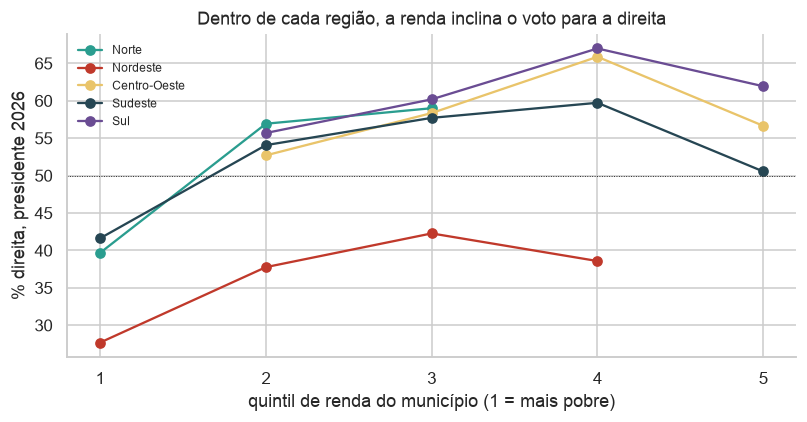

In [3]:
y26 = pres[pres.ano == 2026]
t = y26.groupby(["q", "reg"]).apply(lambda x: pd.Series({"dir": w(x, "dir"), "esq": w(x, "esq"), "mi": x.tot.sum() / 1e6}))
print("% direita, presidente 2026"); print(t["dir"].unstack("reg").round(1).to_string())
print("\n% esquerda, presidente 2026"); print(t["esq"].unstack("reg").round(1).to_string())
print("\nVotos válidos (milhões) em cada célula"); print(t["mi"].unstack("reg").round(1).to_string())

fig, ax = plt.subplots(figsize=(7.5, 4))
for r, c in zip(REG, ["#2a9d8f", "#c0392b", "#e9c46a", "#264653", "#6a4c93"]):
    s = t["dir"].unstack("reg")[r]; n = t["mi"].unstack("reg")[r]
    ax.plot(s.index[n > 0.3], s[n > 0.3], marker="o", label=r, color=c)
ax.axhline(50, color="k", lw=.6, ls=":"); ax.set_xlabel("quintil de renda do município (1 = mais pobre)"); ax.set_ylabel("% direita, presidente 2026")
ax.set_title("Dentro de cada região, a renda inclina o voto para a direita")
ax.legend(frameon=False, fontsize=8); ax.set_xticks(range(1, 6)); plt.tight_layout(); plt.show()

**Como ler:** em toda região a direita sobe do quintil 1 para o 2, e fora do Nordeste o quintil 2 já tem maioria de direita. Nordeste é a exceção que puxa o quintil 1 para baixo (28% de direita). Parte do que parece "pobre vota na esquerda" é, na verdade, "Nordeste vota na esquerda": região e renda estão misturadas, e a análise por região é obrigatória.

(Células com menos de 300 mil votos válidos foram omitidas do gráfico; estão na tabela.)

## 4. Quem forma a base de cada lado? Composição dos votos por faixa de renda

A pergunta "o pobre vota na direita?" muda de cara quando olhamos **de onde vêm os votos** de cada candidato (2026), em vez de **quanto cada lugar dá**.

De que quintil de renda vêm os votos (presidente 2026, % do total de cada bloco)
   esquerda  direita  eleitorado
q                               
1      30.5     12.8        20.8
2      20.3     20.2        20.2
3      16.7     22.6        19.9
4      15.4     23.4        19.7
5      17.1     21.1        19.5

Quintis 1+2 (40% mais pobres em renda municipal): 51% dos votos de esquerda e 33% dos votos de direita.
Votos de direita em municípios dos quintis 1+2: 19.5 milhões
  dos quais fora do Nordeste: 11.4 milhões


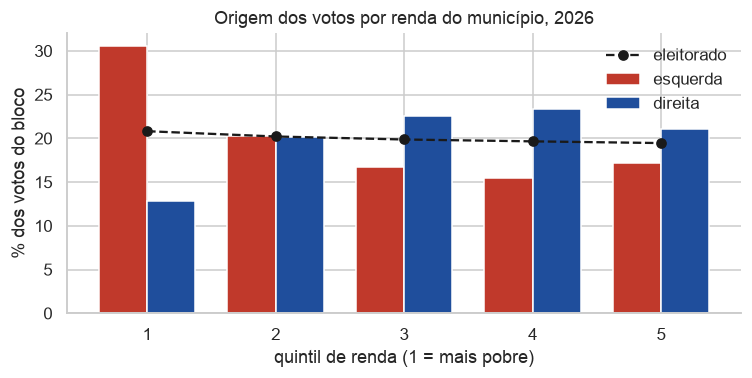

In [4]:
comp = {}
for k in ("esquerda", "direita"):
    s = y26.groupby("q")[k].sum()
    comp[k] = 100 * s / s.sum()
comp["eleitorado"] = 100 * y26.groupby("q").tot.sum() / y26.tot.sum()
comp = pd.DataFrame(comp)
print("De que quintil de renda vêm os votos (presidente 2026, % do total de cada bloco)"); print(comp.round(1).to_string())
pob = comp.loc[[1, 2]].sum()
print(f"\nQuintis 1+2 (40% mais pobres em renda municipal): {pob['esquerda']:.0f}% dos votos de esquerda e {pob['direita']:.0f}% dos votos de direita.")
print(f"Votos de direita em municípios dos quintis 1+2: {y26[y26.q <= 2].direita.sum()/1e6:.1f} milhões")
print(f"  dos quais fora do Nordeste: {y26[(y26.q <= 2) & (y26.reg != 'Nordeste')].direita.sum()/1e6:.1f} milhões")
ax = comp[["esquerda", "direita"]].plot.bar(color=[COR["esquerda"], COR["direita"]], figsize=(7, 3.6), width=.75)
ax.set_xlabel("quintil de renda (1 = mais pobre)"); ax.set_ylabel("% dos votos do bloco"); ax.set_title("Origem dos votos por renda do município, 2026")
ax.plot(range(5), comp.eleitorado, "k--", marker="o", label="eleitorado"); ax.legend(frameon=False); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

**Como ler:** o eleitorado é dividido igualmente por construção (20% por quintil). A esquerda depende desproporcionalmente do quintil 1 (30% dos seus votos); a direita, dos quintis 3 e 4 (23% cada). Mas 33% dos votos da direita vêm de municípios pobres (quintis 1+2), um volume grande em números absolutos.

## 5. É só o presidente? Voto em cada cargo nos municípios mais pobres

Nos notebooks anteriores vimos que a mudança de voto é maior para presidente do que para o Legislativo. Aqui o mesmo corte por renda: % de direita por cargo e quintil.

In [5]:
ordem = ["presidente", "governador", "senador", "dep_federal", "dep_estadual"]
for y in (2022, 2026):
    t = d[d.ano == y].groupby(["cargo", "q"]).apply(lambda x: w(x, "dir")).unstack("q").loc[ordem]
    print(f"% direita por cargo e quintil de renda — {y}"); print(t.round(1).to_string()); print()
t = pd.concat({y: d[d.ano == y].groupby(["cargo", "q"]).apply(lambda x: w(x, "dir")).unstack("q").loc[ordem, 1] for y in (2014, 2018, 2022, 2026)}, axis=1)
print("Quintil mais pobre: % direita por cargo ao longo do tempo"); print(t.round(1).to_string())

% direita por cargo e quintil de renda — 2022
q               1    2    3    4    5
cargo                                
presidente   24.9 44.3 50.2 53.1 48.7
governador   31.4 49.8 49.9 51.9 42.9
senador      33.2 52.7 54.6 59.0 53.0
dep_federal  47.4 48.0 47.4 47.4 47.1
dep_estadual 37.5 44.4 43.8 44.8 45.0

% direita por cargo e quintil de renda — 2026
q               1    2    3    4    5
cargo                                
presidente   30.5 49.6 56.3 59.0 53.7
governador   24.4 44.9 50.7 61.8 53.3
senador      38.6 51.3 57.8 62.4 55.7
dep_federal  40.5 49.9 51.4 53.5 47.3
dep_estadual 32.0 45.3 46.1 48.0 45.9

Quintil mais pobre: % direita por cargo ao longo do tempo
              2014  2018  2022  2026
cargo                               
presidente     0.8  22.5  24.9  30.5
governador    15.0  14.8  31.4  24.4
senador       12.2  18.3  33.2  38.6
dep_federal   31.3  36.1  47.4  40.5
dep_estadual  31.6  35.2  37.5  32.0


**Como ler:** para presidente, o quintil mais pobre é o menos de direita. Para deputado federal, praticamente não há diferença entre pobres e ricos (47% em 2022). Ou seja, os municípios mais pobres votam em Lula para presidente, mas elegem, via deputados, uma bancada com proporção de direita parecida com a dos mais ricos. O voto presidencial é o mais "polarizado por renda"; o legislativo é muito menos. Isso pode ter relação com voto personalista/local, mas aqui não dá para testar.

## 6. Renda, cor/raça, religião ou escolaridade? O que separa os municípios dentro do mesmo estado

Regressão da % de esquerda no voto presidencial em cada eleição, com efeitos fixos de UF (compara municípios do **mesmo estado**), ponderada por votos. Variáveis padronizadas: o coeficiente é a mudança em p.p. de esquerda para +1 desvio-padrão. Renda em log. Correlação alta entre as variáveis; ler como associação, não como efeito causal.

Coeficientes (p.p. de esquerda por +1 DP), dentro de cada UF
                   2006  2010  2014  2018  2022  2026
renda (log)        -2.8  -2.2  -4.6  -0.9  -1.7  -2.0
% pretos e pardos  10.3   8.9   8.7  11.6  10.4  10.0
% evangélicos      -0.4  -0.3  -0.4  -5.3  -5.8  -5.6
% instrução baixa  -4.0  -4.2  -2.9   0.5  -1.0  -2.3
% urbano           -1.1  -2.7  -1.6  -4.8  -3.4  -3.8

Só renda (+UF), sem os outros controles: {2006: np.float64(-0.9), 2010: np.float64(-0.8), 2014: np.float64(-3.9), 2018: np.float64(-6.1), 2022: np.float64(-4.4), 2026: np.float64(-3.6)}
R² do modelo completo: {2006: np.float64(0.78), 2010: np.float64(0.7), 2014: np.float64(0.82), 2018: np.float64(0.88), 2022: np.float64(0.82), 2026: np.float64(0.82)}


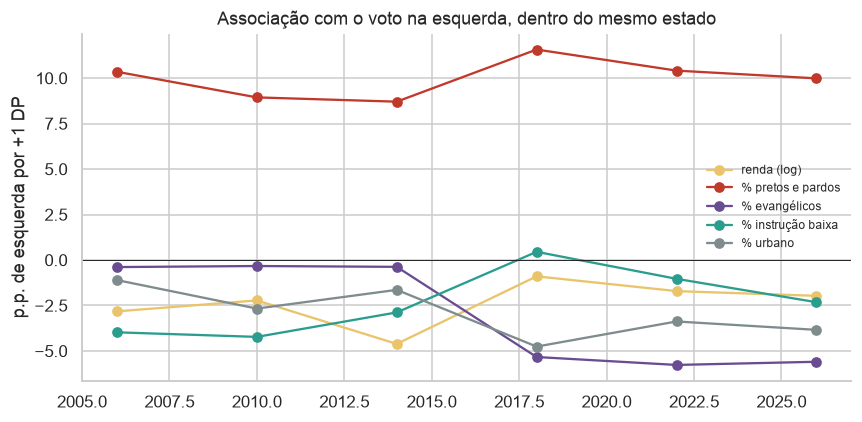

In [6]:
dd = pres.dropna(subset=["pct_evang", "pct_inst_baixa", "pct_preta_parda", "pct_urbano"]).copy()
dd["lrenda"] = np.log(dd.renda)
VARS = {"lrenda": "renda (log)", "pct_preta_parda": "% pretos e pardos", "pct_evang": "% evangélicos",
        "pct_inst_baixa": "% instrução baixa", "pct_urbano": "% urbano"}
for c in VARS: dd["z_" + c] = (dd[c] - dd[c].mean()) / dd[c].std()
f = "esq ~ " + " + ".join("z_" + c for c in VARS) + " + C(SG_UF)"
coef, solo, r2 = {}, {}, {}
for y in (2006, 2010, 2014, 2018, 2022, 2026):
    g = dd[dd.ano == y]
    r = smf.wls(f, g, weights=g.tot).fit(); coef[y] = r.params[["z_" + c for c in VARS]].rename(lambda s: VARS[s[2:]]); r2[y] = r.rsquared
    solo[y] = smf.wls("esq ~ z_lrenda + C(SG_UF)", g, weights=g.tot).fit().params["z_lrenda"]
coef = pd.DataFrame(coef)
print("Coeficientes (p.p. de esquerda por +1 DP), dentro de cada UF"); print(coef.round(1).to_string())
print("\nSó renda (+UF), sem os outros controles:", {y: round(s, 1) for y, s in solo.items()})
print("R² do modelo completo:", {y: round(s, 2) for y, s in r2.items()})
fig, ax = plt.subplots(figsize=(8, 4))
for c, col in zip(coef.index, ["#e9c46a", "#c0392b", "#6a4c93", "#2a9d8f", "#7f8c8d"]):
    ax.plot(coef.columns, coef.loc[c], marker="o", label=c, color=col)
ax.axhline(0, color="k", lw=.6); ax.set_ylabel("p.p. de esquerda por +1 DP"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Associação com o voto na esquerda, dentro do mesmo estado"); plt.tight_layout(); plt.show()

**Como ler:** a variável mais associada ao voto na esquerda dentro do estado é **% de pretos e pardos**, estável desde 2006. Religião evangélica passa a pesar só em 2018. Renda, **depois de controlar por esses fatores**, pesa pouco. Atenção: renda, instrução e cor/raça andam juntas no Brasil, então "renda pesa pouco" aqui quer dizer "a renda média do município, descontados cor, religião e escolaridade, acrescenta pouco". Não quer dizer que renda não importa.

## 7. Dentro dos municípios mais pobres: o que separa o pobre-de-esquerda do pobre-de-direita (do lugar)?

Restrinjo a municípios abaixo da mediana de renda (metade mais pobre dos municípios) e olho a direita em 2026.

2782 municípios, 35.4 milhões de votos válidos; direita 35.1%

Direita 2026, metade mais pobre dos municípios (p.p. por +1 DP, dentro da UF)
renda (log)          9.9
% pretos e pardos   -3.6
% evangélicos        4.8
% instrução baixa    3.2
% urbano             1.5

Extremos nos municípios pobres FORA do Nordeste (pop > 20 mil):
      NM_MUNICIPIO SG_UF  renda  pct_evang  pct_preta_parda  dir  esq
            URUARÁ    PA 1111.2       39.2             77.9 78.1 19.6
      RORAINÓPOLIS    RR 1141.6       38.8             79.0 74.4 22.6
SÃO FÉLIX DO XINGU    PA 1285.4       38.3             77.8 73.4 23.6
       ALTO ALEGRE    RR  749.8       20.7             34.0 72.9 24.0
      MEDICILÂNDIA    PA 1010.4       43.3             79.5 72.9 24.2
MACHADINHO D OESTE    RO 1350.4       47.4             73.1 72.3 24.0
         CARACARAÍ    RR 1003.7       39.1             77.7 72.2 24.6
    SENA MADUREIRA    AC 1070.9       36.9             80.4 71.9 24.6


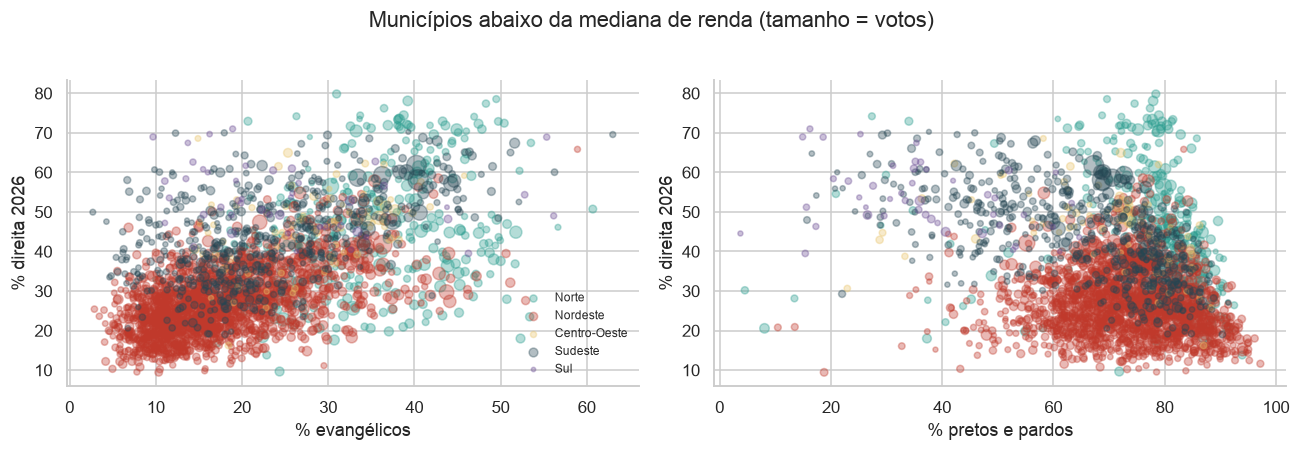

In [7]:
g = dd[(dd.ano == 2026) & (dd.renda < dd.renda.median())]
print(f"{len(g)} municípios, {g.tot.sum()/1e6:.1f} milhões de votos válidos; direita {100*g.direita.sum()/g.tot.sum():.1f}%")
r = smf.wls("dir ~ " + " + ".join("z_" + c for c in VARS) + " + C(SG_UF)", g, weights=g.tot).fit()
print("\nDireita 2026, metade mais pobre dos municípios (p.p. por +1 DP, dentro da UF)")
print(r.params[["z_" + c for c in VARS]].rename(lambda s: VARS[s[2:]]).round(1).to_string())
print("\nExtremos nos municípios pobres FORA do Nordeste (pop > 20 mil):")
ne = g[(g.reg != "Nordeste") & (g["pop"] > 20000)]
print(ne.sort_values("dir", ascending=False)[["NM_MUNICIPIO", "SG_UF", "renda", "pct_evang", "pct_preta_parda", "dir", "esq"]].head(8).round(1).to_string(index=False))
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, c, nm in zip(axs, ["pct_evang", "pct_preta_parda"], ["% evangélicos", "% pretos e pardos"]):
    for rg, col in zip(REG, ["#2a9d8f", "#c0392b", "#e9c46a", "#264653", "#6a4c93"]):
        s = g[g.reg == rg]; ax.scatter(s[c], s["dir"], s=np.sqrt(s.tot) / 4, alpha=.35, color=col, label=rg)
    ax.set_xlabel(nm); ax.set_ylabel("% direita 2026")
axs[0].legend(frameon=False, fontsize=8, markerscale=.6); fig.suptitle("Municípios abaixo da mediana de renda (tamanho = votos)", y=1.02)
plt.tight_layout(); plt.show()

**Como ler:** entre os municípios pobres, os *menos* pobres (e mais evangélicos, e com mais instrução baixa) votam mais na direita, e os mais pretos/pardos votam menos. Os campeões fora do Nordeste são municípios de fronteira agrícola/extrativista do Norte (PA, RR, RO, AC), pobres em renda média, evangélicos e com eleitorado majoritariamente preto e pardo. Isso quebra a ideia de que "pobre de direita" seja sinônimo de "branco" ou "rico": é um perfil regional e religioso específico.

## 8. O que este notebook **não** consegue responder, e como seguir

| Hipótese comum sobre o "pobre de direita" | O que os dados de município dizem | O que falta |
|---|---|---|
| Valores/religião (evangélicos) | Associação forte com a direita a partir de 2018 (seção 6) | Survey: o evangélico pobre vota assim por religião ou por outro motivo? |
| Segurança pública / crime | Candidatos com título de segurança no nome crescem (notebook anterior) | Taxa de homicídios por município (Atlas da Violência/SINESP) cruzada com o voto |
| Antipetismo / corrupção | Não testável com votos | Survey (ESEB tem pergunta de rejeição partidária) |
| Empreendedorismo / trabalho informal, aversão a imposto | Não testável | Censo: % de conta própria/informalidade por município (SIDRA); survey |
| Beneficiários de programa social votam diferente | Municípios mais pobres, que mais recebem Bolsa Família, ficam com a esquerda (seção 2) | % da população no Bolsa Família por município (MDS/CadÚnico) e ver o efeito marginal |
| Cor/raça | O fator mais estável dentro do estado (seção 6) | Survey para separar renda, cor e religião no **mesmo indivíduo** |
| Pobres de cidades grandes (periferias) | Invisível aqui: município grande tem renda média alta | Votação por seção/zona cruzada com escolaridade do eleitorado por seção (TSE `perfil_eleitor_secao`) ou setor censitário |

**Próximos passos que daria para fazer com dados públicos:**
1. **Seção eleitoral × escolaridade** (TSE): dentro de uma mesma cidade, compara seções com eleitorado de baixa escolaridade com as demais. É a melhor *proxy* de classe disponível sem survey, e resolve parte do problema de "cidade rica tem pobre".
2. **Bolsa Família e informalidade por município** como variáveis adicionais.
3. **Microdados de survey** (ESEB 2022, no CESOP/Unicamp; Latinobarómetro; Datafolha quando divulga microdados): aí sim dá para comparar pobres que votam à direita e à esquerda **no nível da pessoa**, que é o que a pergunta original exige.